# Decoupled run: Flory-Schulz (tetra) barriers -> solver
The same run as `km.simulate(T, p, elim_map='flory-tetra')`, taken apart into its three steps:

1. **Barriers**: the Flory-Schulz approximation, one barrier set (tetramerization, `_tetra`) for every insertion and elimination, Gibbs energies at p0 = 1 bar.
2. **Conditions**: pressure enters once, through the GCMC pore concentration of ethylene; product crowding with strength s divides each elimination by gamma = theta_v^-s.
3. **Solver**: the reaction list goes to `Reaction_Diffusion`; out come concentrations over time and the product distribution.

Batch reactor, no diffusion limit (infinite crystal).

In [1]:
import sys
sys.path.insert(0, '../scripts')
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import km_common as km
from kinetic_model.constants.energy_profile import EnergyBarriersSimplifyed
from kinetic_model.core.eyring import Eyring_k
from kinetic_model.core.diffusion import Reaction_Diffusion

T = 340        # K
p = 10         # bar
s = 3          # crowding strength (pocket)
N_MAX = 16
HOURS = 1.0

## 1. Barriers (Flory-Schulz, tetra)
Free-energy barriers of the reduced network from the DFT profile at p0 = 1 bar; the `_tetra` set is used for every chain length.

In [2]:
bp = EnergyBarriersSimplifyed(temperature=T, pressure=1.0).get_energy_barriers()
barriers = {step: (bp[f'{step}_tetra'], bp[f'de{step}_tetra']) for step in ('insertion', 'elimination')}
k = {step: (Eyring_k(gf, T), Eyring_k(gr, T)) for step, (gf, gr) in barriers.items()}
pd.DataFrame({step: {'dG_TS forward (kJ/mol)': barriers[step][0], 'dG_TS reverse (kJ/mol)': barriers[step][1],
                     'k forward (1/s)': k[step][0], 'k reverse (1/s)': k[step][1]} for step in barriers}).T

,dG_TS forward (kJ/mol),dG_TS reverse (kJ/mol),k forward (1/s),k reverse (1/s)
insertion,80.588846,126.531614,2.942326,2.571514e-07
elimination,67.694331,66.599064,281.684752,4.149891e+02


## 2. Pressure and s
Pore ethylene from the GCMC surrogate at (p, T); pore filling theta from its Langmuir fit, gamma = (1 - theta)^-s for every released olefin.

In [3]:
c2_pore = float(km.C2_MODEL.predict_absolute(np.array([p * 1e5]), np.array([float(T)]))[0])   # bar to Pa
theta = km.ethylene_filling(T, p)
gamma = (1 - theta) ** -s
print(f'pore ethylene {c2_pore:.3g}, filling theta {theta:.3f}, gamma {gamma:.3g}')
print('network valid:', km.network_consistency(float(T), float(p))[0])

pore ethylene 46.7, filling theta 0.337, gamma 3.43
network valid: True


## 3. Reaction list and solver
Insertion CatCn(C2) + C2 <-> CatCn+2(C2), elimination CatCn(C2) + C2 <-> CatC2(C2) + Cn (forward constant divided by gamma). The constants are scaled to a maximum of 1e6 1/s for the stiff solver, and time is scaled back.

In [4]:
(kf_ins, kr_ins), (kf_el, kr_el) = k['insertion'], k['elimination']
reactions = [(f'CatC{n}(C2) + C2 <-> CatC{n + 2}(C2)', kf_ins, kr_ins) for n in range(2, N_MAX, 2)]
reactions += [(f'CatC{n}(C2) + C2 <-> CatC2(C2) + C{n}', kf_el / gamma, kr_el) for n in range(4, N_MAX + 1, 2)]

f = min(1.0, 1e6 / max(max(r[1], r[2]) for r in reactions))
reactions = [(eq, kf * f, kr * f) for eq, kf, kr in reactions]
for r in reactions[:2] + reactions[-1:]:
    print(r)

solver = Reaction_Diffusion(reactions=reactions)
t = np.concatenate(([0.0], np.geomspace(1e-2, HOURS * 3600, 499)))   # log-spaced, s
res = solver.solve(initial_concs_dict={'CatC2(C2)': km.CAT, 'C2': c2_pore}, time_points=t / f)
res.index = res.index * f   # real seconds

('CatC2(C2) + C2 <-> CatC4(C2)', 2.942325893813401, 2.571513700223126e-07)
('CatC4(C2) + C2 <-> CatC6(C2)', 2.942325893813401, 2.571513700223126e-07)
('CatC16(C2) + C2 <-> CatC2(C2) + C16', 82.0899645109087, 414.98909116204123)


## Concentrations over time

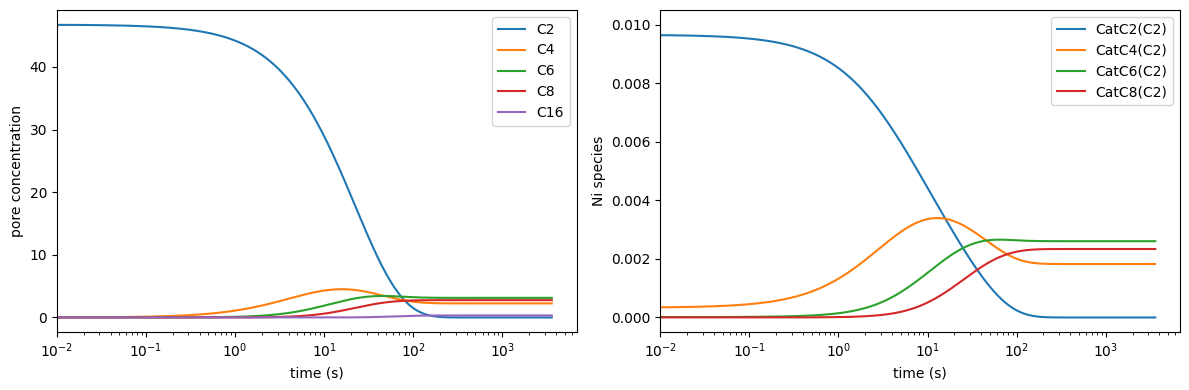

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for sp in ('C2', 'C4', 'C6', 'C8', 'C16'):
    axs[0].plot(res.index, res[sp], label=sp)
axs[0].set_xlabel('time (s)'); axs[0].set_ylabel('pore concentration'); axs[0].legend()
for sp in ('CatC2(C2)', 'CatC4(C2)', 'CatC6(C2)', 'CatC8(C2)'):
    axs[1].plot(res.index, res[sp], label=sp)
axs[1].set_xlabel('time (s)'); axs[1].set_ylabel('Ni species'); axs[1].legend()
for ax in axs: ax.set_xscale('log'); ax.set_xlim(1e-2, None)
plt.tight_layout()

## Product distribution

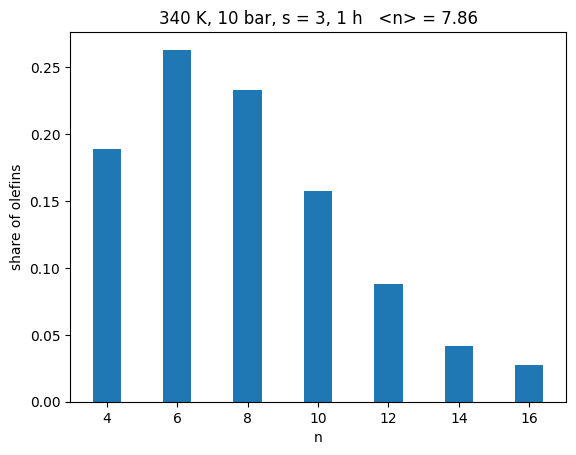

In [6]:
olefins = res[[f'C{n}' for n in range(4, N_MAX + 1, 2)]].iloc[-1]
dist = pd.DataFrame({'n': [int(c[1:]) for c in olefins.index], 'probability': (olefins / olefins.sum()).to_numpy()})
mean_n = (dist.n * dist.probability).sum()
plt.bar(dist.n, dist.probability)
plt.xlabel('n'); plt.ylabel('share of olefins'); plt.title(f'{T} K, {p} bar, s = {s}, {HOURS:g} h   <n> = {mean_n:.2f}');

## Check against `km.simulate`

In [7]:
dist_ref, _ = km.simulate(T, p, n_max=N_MAX, elim_map='flory-tetra', s_pocket=s, hours=HOURS, n_steps=500)
print(f'decoupled <n> = {mean_n:.3f}, km.simulate <n> = {km.mean_length(dist_ref):.3f}')

decoupled <n> = 7.855, km.simulate <n> = 7.855
